<a href="https://colab.research.google.com/github/Mrudhulraj/llm-caching/blob/main/stage3_grpo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 3 — Transparent GRPO: Three Controlled Experiments (Google Colab)

English translation and Colab adaptation of the supplied Stage 3 script. Runs **K1 vs K3**, **1/3/10 inner epochs**, and **clip epsilon 0.1/0.2/0.3** on the 3-digit addition task using **Qwen2.5-0.5B-Instruct**.

**Before running:** Runtime → Change runtime type → **T4 GPU** (or better). Run cells top-to-bottom. No local `/data/models` or `transparent_grpo.py` file is needed. The model is downloaded automatically from Hugging Face. The training loop is self-contained.

**Important methodological corrections:** The source's K3 KL term was detached (so it had no gradient), and its padding/EOS mask could omit valid completion tokens. This version fixes both, uses a nonnegative K3 estimator, and uses a frozen base model as reference through LoRA adapter disabling to avoid a second full model in GPU memory. K1 is the sampled log-ratio penalty in reward, not an unbiased per-sample KL measurement. This is an educational implementation, not a drop-in equivalent of TRL's optimized GRPOTrainer.

## 1. Install dependencies (first run only)

In [13]:
%pip -q install "transformers>=4.46,<5" "peft>=0.13,<1" "accelerate>=1.0,<2" "huggingface_hub>=0.26" pandas matplotlib tqdm

## 2. Imports, GPU check, and reproducibility

In [14]:
import os, gc, random, re, time, json
from contextlib import nullcontext
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
from huggingface_hub import snapshot_download

assert torch.cuda.is_available(), "GPU required: Runtime > Change runtime type > T4 GPU"
DEVICE = torch.device("cuda")
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
MODEL_DIR = "/content/models/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("/content/grpo_stage3_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
print("GPU:", torch.cuda.get_device_name(0), "| dtype:", DTYPE, "| free/total GiB:", [round(x/2**30,2) for x in torch.cuda.mem_get_info()])

GPU: Tesla T4 | dtype: torch.bfloat16 | free/total GiB: [13.67, 14.56]


## 3. Download the model automatically (no assumed local files)

In [15]:
# Downloads the public model into Colab's local disk; subsequent runs reuse cached files.
MODEL_PATH = snapshot_download(repo_id=MODEL_ID, local_dir=MODEL_DIR)
print("Model available at:", MODEL_PATH)
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH, padding_side="left")
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print("EOS token:", tokenizer.eos_token_id, "| pad token:", tokenizer.pad_token_id)

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Model available at: /content/models/Qwen2.5-0.5B-Instruct
EOS token: 151645 | pad token: 151643


## 4. Addition dataset and exact-answer reward

In [16]:
def generate_addition_dataset(n=200, seed=42):
    rng = random.Random(seed)
    return [(f"What is {a}+{b}? Answer with just the number.", str(a+b))
            for a,b in ((rng.randint(100,999), rng.randint(100,999)) for _ in range(n))]

def compute_reward_addition(texts, answers):
    # Preserve the source's last-number reward rule.
    return [float(bool((nums := re.findall(r"\d+", text)) and nums[-1] == ans))
            for text,ans in zip(texts,answers)]

DATA = generate_addition_dataset()
print(DATA[:3])

[('What is 754+214? Answer with just the number.', '968'), ('What is 125+859? Answer with just the number.', '984'), ('What is 381+350? Answer with just the number.', '731')]


## 5. Training configuration — quick smoke test or full comparisons

In [17]:
# First run with QUICK_TEST=True to verify every experiment. Then set False for the source's 30 steps each.
QUICK_TEST = False
NUM_STEPS = 2 if QUICK_TEST else 30
GROUP_SIZE = 4
MAX_NEW_TOKENS = 16
LEARNING_RATE = 5e-5  # LoRA parameters; original full-model script used 5e-6
BETA = 0.1
LOG_EVERY = 1 if QUICK_TEST else 5
print("Training steps per experiment:", NUM_STEPS, "| experiments: 8")

Training steps per experiment: 30 | experiments: 8


## 6. Core GRPO functions — self-contained implementation

In [18]:
def selected_log_probs(model, ids, attention_mask):
    out = model(input_ids=ids, attention_mask=attention_mask, use_cache=False)
    logits = out.logits[:, :-1, :].float()
    targets = ids[:, 1:]
    return F.log_softmax(logits, dim=-1).gather(-1, targets.unsqueeze(-1)).squeeze(-1)

def completion_mask(ids, prompt_len, eos_id):
    # Include generated EOS itself, but exclude tokens following EOS (including padding).
    comp = ids[:, prompt_len:]
    eos = comp.eq(eos_id)
    valid = (eos.cumsum(dim=1) - eos.long()).eq(0)
    mask = torch.zeros((ids.size(0), ids.size(1)-1), device=ids.device, dtype=torch.float32)
    mask[:, prompt_len-1:] = valid.float()
    return mask

def load_policy():
    base = AutoModelForCausalLM.from_pretrained(MODEL_PATH, torch_dtype=DTYPE, low_cpu_mem_usage=True).to(DEVICE)
    base.config.use_cache = False
    config = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.0,
                        target_modules=["q_proj","v_proj"], bias="none", task_type="CAUSAL_LM")
    model = get_peft_model(base, config)
    model.gradient_checkpointing_enable()
    model.enable_input_require_grads()
    return model

def run_grpo_experiment(name, group_size=GROUP_SIZE, learning_rate=LEARNING_RATE,
                        beta=BETA, clip_epsilon=0.2, inner_update_epochs=3,
                        num_steps=NUM_STEPS, max_new_tokens=MAX_NEW_TOKENS,
                        kl_mode="K1", log_every=LOG_EVERY):
    assert kl_mode in ("K1", "K3")
    print(f"\n=== {name}: KL={kl_mode}, epochs={inner_update_epochs}, clip={clip_epsilon} ===", flush=True)
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    model = load_policy()
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=learning_rate)
    metrics = {k: [] for k in ["loss", "reward", "kl", "raw_reward", "grad_norm"]}
    try:
        for step in range(num_steps):
            prompt, answer = DATA[step % len(DATA)]
            formatted = tokenizer.apply_chat_template([{"role":"user", "content":prompt}],
                                                      tokenize=False, add_generation_prompt=True)
            inputs = tokenizer(formatted, return_tensors="pt").to(DEVICE)
            prompt_len = inputs.input_ids.shape[1]
            model.eval()
            with torch.no_grad():
                generated = model.generate(input_ids=inputs.input_ids.repeat(group_size,1),
                                           attention_mask=inputs.attention_mask.repeat(group_size,1),
                                           max_new_tokens=max_new_tokens, do_sample=True,
                                           temperature=0.8, top_p=1.0,
                                           pad_token_id=tokenizer.pad_token_id,
                                           eos_token_id=tokenizer.eos_token_id,
                                           use_cache=True)
                comp = generated[:, prompt_len:]
                completions = tokenizer.batch_decode(comp, skip_special_tokens=True)
                rewards = torch.tensor(compute_reward_addition(completions,[answer]*group_size),device=DEVICE)
                mask = completion_mask(generated, prompt_len, tokenizer.eos_token_id)
                # Attention is valid through EOS; pad==eos means token ID alone cannot determine padding.
                attn = torch.cat([torch.ones((group_size,prompt_len),device=DEVICE,dtype=torch.long),
                                  mask[:,prompt_len-1:].long()], dim=1)
                old_lp = selected_log_probs(model, generated, attn).detach()
                with model.disable_adapter():
                    ref_lp = selected_log_probs(model, generated, attn).detach()
                sampled_kl = ((old_lp-ref_lp)*mask).sum(dim=1)
                if kl_mode == "K1":
                    adjusted = rewards - beta * sampled_kl
                else:
                    adjusted = rewards
                advantages = (adjusted-adjusted.mean()) / (adjusted.std(unbiased=False)+1e-4)
            model.train()
            losses=[]; norms=[]
            for epoch in range(inner_update_epochs):
                lp = selected_log_probs(model, generated, attn)
                ratio = (lp-old_lp).clamp(-20,20).exp()
                adv = advantages[:,None]
                surr = torch.minimum(ratio*adv, ratio.clamp(1-clip_epsilon,1+clip_epsilon)*adv)
                loss = -(surr*mask).sum() / mask.sum().clamp_min(1)
                if kl_mode == "K3":
                    # Nonnegative Schulman k3 estimator: exp(ref_logp - policy_logp) - (ref_logp - policy_logp) - 1.
                    # Critically: DO NOT detach lp; KL must backpropagate into policy.
                    log_r = (ref_lp-lp).clamp(-20,20)
                    k3 = log_r.exp() - log_r - 1
                    loss = loss + beta*(k3*mask).sum()/mask.sum().clamp_min(1)
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
                optimizer.step()
                losses.append(float(loss.detach())); norms.append(float(norm))
            metrics["loss"].append(float(np.mean(losses)))
            metrics["reward"].append(float(rewards.mean()))
            metrics["raw_reward"].append(float(rewards.mean()))
            metrics["kl"].append(float(sampled_kl.mean()))  # sampled log-ratio, not exact KL
            metrics["grad_norm"].append(float(np.mean(norms)))
            if step % log_every == 0 or step == num_steps-1:
                print(f"Step {step+1:3}/{num_steps} | loss={metrics['loss'][-1]:.4f} | "
                      f"reward={metrics['reward'][-1]:.3f} | sampledKL={metrics['kl'][-1]:.4f} | "
                      f"grad={metrics['grad_norm'][-1]:.3f}", flush=True)
    finally:
        del optimizer, model
        gc.collect(); torch.cuda.empty_cache()
    return metrics

## 7. Run Experiment 1 — K1 (KL in reward) vs K3 (KL in loss)

In [19]:
!pip install torchao==0.16.0

In [20]:
results = {}
results["K1"] = run_grpo_experiment("K1: KL in reward", kl_mode="K1")
results["K3"] = run_grpo_experiment("K3: KL in loss", kl_mode="K3")


=== K1: KL in reward: KL=K1, epochs=3, clip=0.2 ===
Step   1/30 | loss=0.0000 | reward=0.000 | sampledKL=0.0000 | grad=0.000
Step   6/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0012 | grad=0.000
Step  11/30 | loss=0.0000 | reward=1.000 | sampledKL=-0.0002 | grad=0.000
Step  16/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0014 | grad=0.000
Step  21/30 | loss=-0.0205 | reward=0.250 | sampledKL=0.8916 | grad=6.803
Step  26/30 | loss=0.0000 | reward=1.000 | sampledKL=0.5160 | grad=0.000
Step  30/30 | loss=0.0000 | reward=1.000 | sampledKL=-0.0013 | grad=0.000

=== K3: KL in loss: KL=K3, epochs=3, clip=0.2 ===
Step   1/30 | loss=0.0000 | reward=0.000 | sampledKL=0.0000 | grad=0.000
Step   6/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0032 | grad=0.000
Step  11/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0018 | grad=0.000
Step  16/30 | loss=0.0000 | reward=1.000 | sampledKL=-0.0077 | grad=0.000
Step  21/30 | loss=0.0005 | reward=0.000 | sampledKL=0.1309 | grad=0.246
Step  26/30 | lo

## 8. Run Experiment 2 — Inner update epochs: 1 vs 3 vs 10

In [21]:
for epochs in (1,3,10):
    results[f"epoch_{epochs}"] = run_grpo_experiment(f"inner_update_epochs={epochs}", inner_update_epochs=epochs)


=== inner_update_epochs=1: KL=K1, epochs=1, clip=0.2 ===
Step   1/30 | loss=0.0000 | reward=0.000 | sampledKL=0.0000 | grad=0.000
Step   6/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0035 | grad=0.000
Step  11/30 | loss=0.0000 | reward=1.000 | sampledKL=-0.0010 | grad=0.000
Step  16/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0026 | grad=0.000
Step  21/30 | loss=0.0000 | reward=0.250 | sampledKL=0.6817 | grad=16.884
Step  26/30 | loss=0.0000 | reward=1.000 | sampledKL=0.4454 | grad=0.000
Step  30/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0024 | grad=0.000

=== inner_update_epochs=3: KL=K1, epochs=3, clip=0.2 ===
Step   1/30 | loss=0.0000 | reward=0.000 | sampledKL=0.0000 | grad=0.000
Step   6/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0012 | grad=0.000
Step  11/30 | loss=0.0000 | reward=1.000 | sampledKL=-0.0002 | grad=0.000
Step  16/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0014 | grad=0.000
Step  21/30 | loss=-0.0205 | reward=0.250 | sampledKL=0.8916 | grad=6.803
Step

## 9. Run Experiment 3 — PPO clip epsilon: 0.1 vs 0.2 vs 0.3

In [22]:
for clip in (0.1,0.2,0.3):
    results[f"clip_{clip}"] = run_grpo_experiment(f"clip_epsilon={clip}", clip_epsilon=clip)


=== clip_epsilon=0.1: KL=K1, epochs=3, clip=0.1 ===
Step   1/30 | loss=0.0000 | reward=0.000 | sampledKL=0.0000 | grad=0.000
Step   6/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0026 | grad=0.000
Step  11/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0022 | grad=0.000
Step  16/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0034 | grad=0.000
Step  21/30 | loss=-0.0117 | reward=0.250 | sampledKL=0.9228 | grad=5.919
Step  26/30 | loss=0.0000 | reward=1.000 | sampledKL=0.4213 | grad=0.000
Step  30/30 | loss=0.0000 | reward=1.000 | sampledKL=-0.0604 | grad=0.000

=== clip_epsilon=0.2: KL=K1, epochs=3, clip=0.2 ===
Step   1/30 | loss=0.0000 | reward=0.000 | sampledKL=0.0000 | grad=0.000
Step   6/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0012 | grad=0.000
Step  11/30 | loss=0.0000 | reward=1.000 | sampledKL=-0.0002 | grad=0.000
Step  16/30 | loss=0.0000 | reward=1.000 | sampledKL=0.0014 | grad=0.000
Step  21/30 | loss=-0.0205 | reward=0.250 | sampledKL=0.8916 | grad=6.803
Step  26/30 | 

## 10. Summary, plots, and CSV/JSON export

,experiment,early_reward,late_reward,max_sampled_kl,mean_loss,mean_grad_norm
0,K1,0.675,0.825,1.511414,-0.003098,2.657014
1,K3,0.675,0.775,2.162926,-0.005317,2.499554
2,epoch_1,0.675,0.800,0.707504,-0.018754,5.509237
3,epoch_3,0.675,0.825,1.511414,-0.003098,2.657014
4,epoch_10,0.675,0.875,10.574902,0.034423,0.888878
5,clip_0.1,0.675,0.775,2.843734,-0.019469,3.077818
6,clip_0.2,0.675,0.825,1.511414,-0.003098,2.657014
7,clip_0.3,0.675,0.875,3.455985,0.012505,2.793809


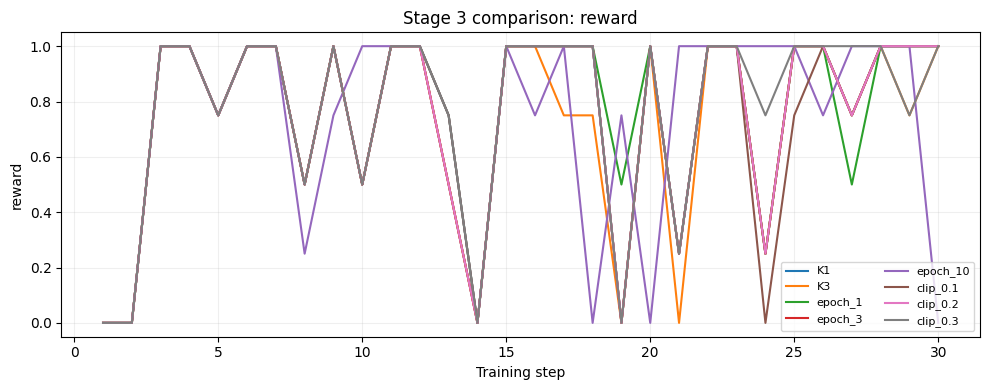

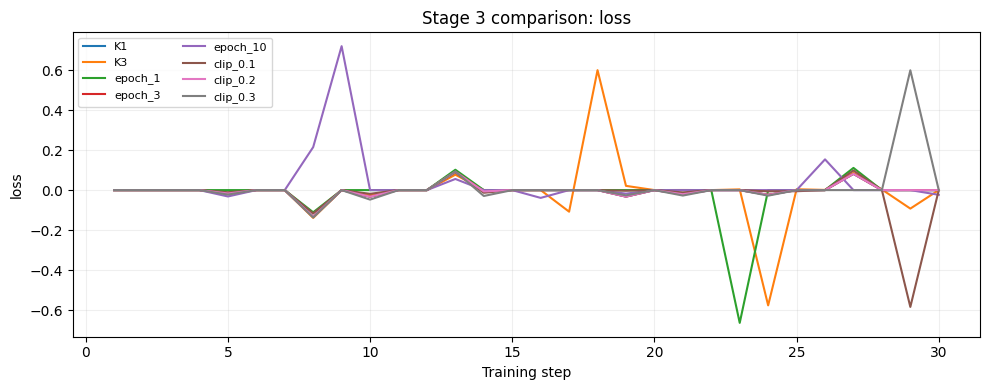

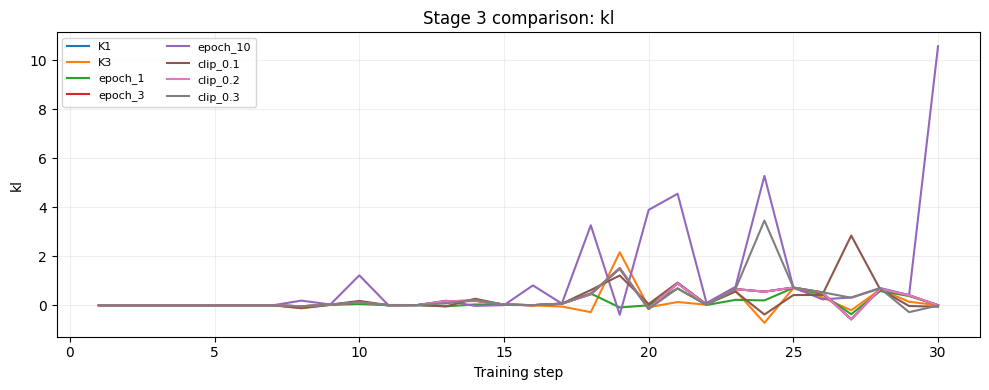

Saved results in: /content/grpo_stage3_results


In [23]:
def summarize(name, m):
    n = min(10, len(m["reward"]))
    return {"experiment":name, "early_reward":float(np.mean(m["reward"][:n])),
            "late_reward":float(np.mean(m["reward"][-n:])),
            "max_sampled_kl":float(max(m["kl"])), "mean_loss":float(np.mean(m["loss"])),
            "mean_grad_norm":float(np.mean(m["grad_norm"]))}
summary = pd.DataFrame([summarize(k,v) for k,v in results.items()])
display(summary)
summary.to_csv(OUTPUT_DIR/"experiment_summary.csv",index=False)
with open(OUTPUT_DIR/"experiment_metrics.json","w") as f: json.dump(results,f,indent=2)
for metric in ("reward","loss","kl"):
    plt.figure(figsize=(10,4))
    for name,m in results.items(): plt.plot(range(1,len(m[metric])+1),m[metric],label=name)
    plt.title(f"Stage 3 comparison: {metric}"); plt.xlabel("Training step"); plt.ylabel(metric)
    plt.legend(ncol=2,fontsize=8); plt.grid(alpha=.2); plt.tight_layout()
    plt.savefig(OUTPUT_DIR/f"{metric}.png",dpi=130); plt.show()
print("Saved results in:", OUTPUT_DIR)

## 11. Download experiment outputs

In [24]:
import shutil
archive = shutil.make_archive("/content/grpo_stage3_results", "zip", OUTPUT_DIR)
print("Created:", archive)
from google.colab import files
files.download(archive)

Created: /content/grpo_stage3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes and limitations
- All eight comparisons start from the same pretrained checkpoint and seeded prompts, but GPU sampling can still vary. **30 steps is illustrative, not a rigorous benchmark.**
- A group with identical rewards has zero reward advantage; on sparse exact-answer addition rewards this can happen frequently. K1 can still have a KL-adjusted signal; K3 may have no policy-gradient signal for that group.
- The original code's `K1` uses a sampled log-probability difference and `K3` here uses a differentiable nonnegative surrogate; these are **different estimators/placements**, so interpret their comparison carefully.
- For a more statistically meaningful comparison, repeat runs across seeds and evaluate on a held-out addition dataset.
- Colab storage is ephemeral. Download results or copy them to Google Drive after completion. To save to Drive: `from google.colab import drive; drive.mount('/content/drive')` and then copy the ZIP to your Drive folder.